# Missing values: overview

Before we fill any gaps, we need to know **why** values are missing (lecture, chapter 2a). This decides which filling method makes sense:

| Type | Meaning | What it means for filling |
|---|---|---|
| MCAR | missing completely at random | simple methods are fine |
| MAR | missingness depends on other columns we can see | use the other columns, or keep the information "missing" |
| MNAR | missingness depends on the missing value itself | every filled value is a guess, keep the information "missing" |

This notebook answers four questions:

1. How much is missing?
2. Are company_size and company_type missing together?
3. major_discipline: is the value missing, or does the question just not apply?
4. Does the missingness depend on other columns?

In week 2 we already checked the company columns against relevant_experience (`missing_company.ipynb`). Here we do it for all columns. We use `customer_train_typed.pkl` from week 2 and don't change or save anything.

## 1. Loading the data

We leave out `gender`: a model that predicts job changes should not use a person's gender (fairness, lecture chapter 1), so we don't analyse or fill it.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_pickle("../week 2/customer_train_typed.pkl")
df = df.drop(columns="gender")
df.shape

(19158, 13)

## 2. How much is missing?

`isna()` marks every missing value as True. `sum()` counts the gaps per column, `mean()` gives the share (True counts as 1, False as 0).

In [18]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "share (%)": (df.isna().mean() * 100).round(1),
})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
missing

,missing,share (%)
company_type,6140,32.0
company_size,5938,31.0
major_discipline,2813,14.7
education_level,460,2.4
last_new_job,423,2.2
enrolled_university,386,2.0
experience,65,0.3


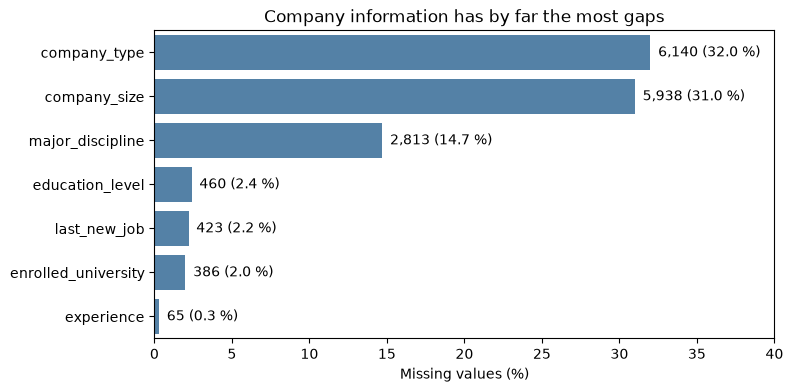

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing["share (%)"], y=missing.index, color="steelblue", ax=ax)

for i, (n, pct) in enumerate(zip(missing["missing"], missing["share (%)"])):
    ax.text(pct + 0.5, i, f"{n:,} ({pct} %)", va="center")

ax.set_title("Company information has by far the most gaps")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
ax.set_xlim(0, 40)
plt.show()

7 of 13 columns have gaps. company_type and company_size are missing for almost a third of the students, the others for at most 15 %.

How many students have at least one gap? This shows what would happen if we simply dropped every incomplete row (`dropna()`).

In [20]:
has_gap = df.isna().any(axis=1)
print(f"Students with at least one gap: {has_gap.sum():,} of {len(df):,} ({has_gap.mean():.1%})")

Students with at least one gap: 7,979 of 19,158 (41.6%)


Dropping incomplete rows would throw away about 42 % of the students. The lecture only recommends deletion for MCAR data with few gaps, so that's not an option here.

## 3. Are company_size and company_type missing together?

If both are empty in the same rows, there is probably one common reason, for example "no employer".

In [21]:
pd.crosstab(
    df["company_size"].isna(),
    df["company_type"].isna(),
    rownames=["company_size missing"],
    colnames=["company_type missing"],
)

company_type missing,False,True
company_size missing,,
False,12440,780
True,578,5360


In 5,360 rows both are missing, only 1,358 rows have just one of them missing. So the two columns mostly go missing together, which fits the "no employer" idea from week 2.

## 4. major_discipline: missing or not applicable?

A study major only exists if someone studied. So we compare the gaps with education_level. `dropna=False` keeps the rows where education_level is missing as well.

In [22]:
pd.crosstab(
    df["education_level"],
    df["major_discipline"].isna(),
    dropna=False,
    rownames=["education level"],
    colnames=["major_discipline missing"],
)

major_discipline missing,False,True
education level,,
NaN,0,460
Primary School,0,308
High School,0,2017
Graduate,11576,22
Masters,4355,6
Phd,414,0


- Primary School (308) and High School (2,017): the major is **always** empty. These students have no major, the question just doesn't apply to them.
- education_level missing (460): major_discipline is missing too.
- Graduate, Masters, Phd: only 28 gaps out of about 16,400 students.

So most of the 2,813 gaps are not real gaps. When filling, "No Major" is the right answer for students without a degree.

## 5. Does the missingness depend on other columns?

Same idea as in `missing_company.ipynb`, now for all columns with gaps. We split the students into two groups and compare the **share of missing values** in each group:

- **relevant_experience** (No / Yes): if the share differs, the gaps are not MCAR.
- **job_change** (No / Yes), our target: if the share differs, the gap itself says something about job changes. Then a filling method should keep the information "missing".

How it works: `isna()` gives True/False, which counts as 1/0. The mean of a 0/1 column is a rate (lecture, chapter 2a), so `groupby(...).mean()` gives the share of gaps per group. The column `difference` is Yes minus No in percentage points. We show the group sizes n next to the rates.

In [23]:
gaps = df[missing.index].isna()

def missing_by(group):
    table = (gaps.groupby(df[group]).mean() * 100).round(1).T
    table.columns = ["missing if No (%)", "missing if Yes (%)"]
    table["difference"] = table["missing if Yes (%)"] - table["missing if No (%)"]
    return table

`groupby` splits the rows by the group column, `mean()` gives the share of gaps per group and column, `.T` turns the table so that every row is one column of our data.

Example: "missing if No" in the job_change table is the share of gaps among all students who don't change their job.

In [24]:
print(df["relevant_experience"].value_counts())
missing_by("relevant_experience")

relevant_experience
True     13792
False     5366
Name: count, dtype: int64


,missing if No (%),missing if Yes (%),difference
company_type,58.9,21.6,-37.3
company_size,62.6,18.7,-43.9
major_discipline,32.4,7.8,-24.6
education_level,4.6,1.5,-3.1
last_new_job,3.7,1.6,-2.1
enrolled_university,3.6,1.4,-2.2
experience,0.4,0.3,-0.1


In [25]:
print(df["job_change"].value_counts())
missing_by("job_change")

job_change
False    14381
True      4777
Name: count, dtype: int64


,missing if No (%),missing if Yes (%),difference
company_type,26.1,49.9,23.8
company_size,24.5,50.5,26.0
major_discipline,15.7,11.5,-4.2
education_level,2.5,2.2,-0.3
last_new_job,1.9,3.2,1.3
enrolled_university,1.8,2.6,0.8
experience,0.3,0.5,0.2


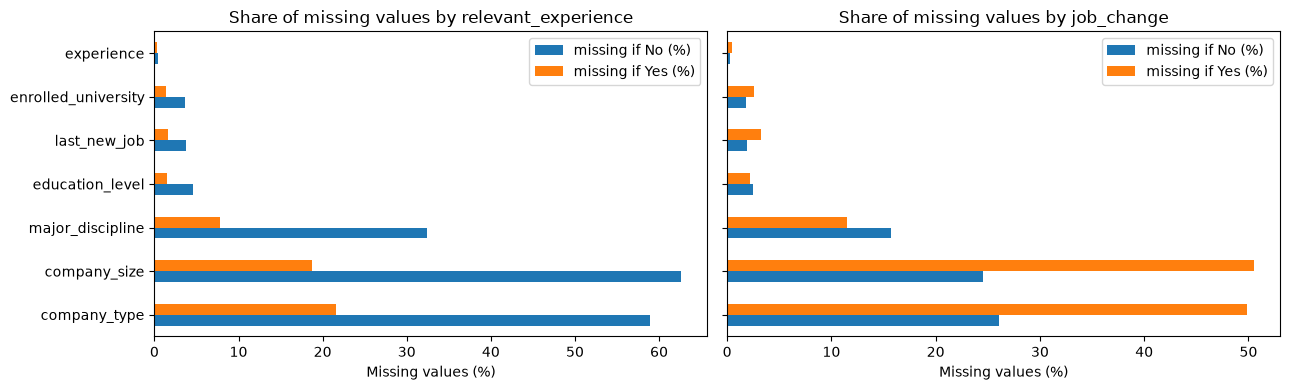

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, group in zip(axes, ["relevant_experience", "job_change"]):
    missing_by(group)[["missing if No (%)", "missing if Yes (%)"]].plot.barh(ax=ax)
    ax.set_title(f"Share of missing values by {group}")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

### Reading the result

We judge the size of the difference: a few percentage points are small, 20 or more are large.

- **company_size, company_type:** by far the biggest differences. Without relevant experience the values are missing about three times as often (about 60 % vs. 20 %, as in week 2). Students who change their job have missing company information **twice as often** (about 50 % vs. 25 %). The gap itself is a hint for job_change.
- **major_discipline:** 32 % vs. 8 % for relevant_experience. This comes from education level (section 4): students who only went to school have no major and also less relevant experience. For job_change the difference is small (16 % vs. 12 %).
- **education_level, enrolled_university, last_new_job (about 2 % gaps):** differences of at most 3 percentage points. Too small to matter in practice.
- **experience (65 rows):** practically no difference. This fits MCAR, but a comparison like this can never prove MCAR.

## 6. Summary

| Column | Missing | Finding | Likely type |
|---|---|---|---|
| company_type | 6,140 (32.0 %) | mostly missing together with company_size, much more often without relevant experience and for job changers | not MCAR, often probably no employer (MNAR) |
| company_size | 5,938 (31.0 %) | same as company_type | not MCAR, often MNAR |
| major_discipline | 2,813 (14.7 %) | almost only students without a degree | mostly "not applicable" |
| education_level | 460 (2.4 %) | small difference for relevant_experience, none for job_change | MAR, few gaps |
| last_new_job | 423 (2.2 %) | small differences for both | MAR, few gaps |
| enrolled_university | 386 (2.0 %) | small differences for both | MAR, few gaps |
| experience | 65 (0.3 %) | no difference found | fits MCAR |

**What this means for filling (next notebook, `missing_values_imputation.ipynb`):**

- Dropping rows is out, 42 % of the students would be lost.
- major_discipline gets a fixed rule: "No Major" for students without a degree.
- For the company columns the gap is information. Filling it with the most common value would hide it, so we compare that with other methods, for example an own category "Unknown".
- For the small columns the method matters less.